# Central fotovoltaica · Corte 3

Ocho pruebas del 19 al 23 de noviembre. Los lotes A y B quedan archivados. Este notebook genera las gráficas, tablas y cifras del análisis vigente.

## 1 · Importación, funciones físicas y limpieza

Las lecturas del ESP32 se cargan desde Excel. La potencia se calcula como V × I, la resistencia como V ÷ I y la energía se integra por trapecios, sin sumar intervalos superiores a 60 s. La tabla incluye las ocho pruebas, aun cuando la cobertura de una sea baja.

In [1]:
import numpy as np
from IPython.display import Image, display
from analisis_vigente import preparar, resumen, modelos, graficar, exportar
from fisica import RAIZ, ohm_v, ohm_i, ohm_r, potencia, energia

assert ohm_v(100, 50) == 5 and ohm_i(5, 50) == 100 and ohm_r(5, 100) == 50
assert potencia(5, 100) == 500
assert abs(energia(np.arange(61), np.full(61, 60))[-1] - 1) < 1e-9

pruebas = preparar()
tabla = resumen(pruebas)
display(tabla[['fuente', 'lecturas', 'validas', 'p_ent_mW', 'energia_ent_mWh', 'r_carga_ohm']].round(2))

,fuente,lecturas,validas,p_ent_mW,energia_ent_mWh,r_carga_ohm
prueba,,,,,,
C1,paneles,3649,3649,193.91,982.48,114.18
C2,bateria,16,13,312.74,5.44,76.45
C3,paneles,1683,1683,289.20,675.86,82.00
C4,bateria,4498,4485,544.73,3329.73,50.20
C5,paneles,5611,5547,315.80,2433.05,84.71
C6,bateria,4974,4954,547.47,3765.48,50.90
C7,paneles,5704,5699,321.82,2546.60,88.74
C8,bateria,7547,7534,379.63,3958.00,74.63


El filtro exige tensión mayor de 0,05 V y corriente directa mayor de 1 mA en ambos puntos, además de valores presentes. Para la visualización se combina una mediana de 5 muestras con una media de 12 muestras por tramos.

## 2 · Eficiencia, descarga y pérdidas

Se divide la potencia media de salida por la de entrada. C4, C6 y C8 aportan al promedio. C2 tiene solo 13 lecturas válidas y se excluye de esa estimación. En cada descarga se ajusta un polinomio de grado 4 al tramo continuo más largo. La autonomía estimada usa la energía media de las otras descargas elegibles.

In [2]:
curvas, autonomia = modelos(pruebas, tabla)
rendimiento = tabla.dropna(subset=['eficiencia_pct'])
display(rendimiento[['p_ent_mW', 'p_sal_mW', 'eficiencia_pct', 'perdida_mW']].round(2))
print('Eficiencia media por prueba:', round(rendimiento.eficiencia_pct.mean(), 2), '%')
display(autonomia.round(2))
display(tabla[['saltos', 'error_energia_pct']].round(2))

,p_ent_mW,p_sal_mW,eficiencia_pct,perdida_mW
prueba,,,,
C4,544.73,472.03,86.66,72.69
C6,547.47,472.57,86.32,74.90
C8,379.63,327.38,86.24,52.25


,medida_h,energia_Wh,potencia_mW,calculada_h,error_pct
prueba,,,,,
C4,5.82,3.15,541.64,5.52,5.51
C6,3.95,2.07,523.21,6.75,41.50
C8,10.31,3.91,379.73,6.88,49.87


,saltos,error_energia_pct
prueba,,
C1,52,0.04
C2,1,4.94
C3,16,0.09
C4,98,0.33
C5,233,0.00
C6,4,0.00
C7,126,0.01
C8,119,0.00


Eficiencia media por prueba: 86.4 %


## 3 · Visualización y validación

Se comparan los cálculos de Python con el registro del ESP32 y la salida con la consigna de 5 V. La estabilidad se calcula con la desviación estándar poblacional de NumPy. Las comparaciones internas no sustituyen el cotejo con multímetro.

,p_ent_mW,p_sal_mW,sigma_sal_mV
fuente,,,
bateria,446.14,386.51,272.02
paneles,280.18,242.59,487.51


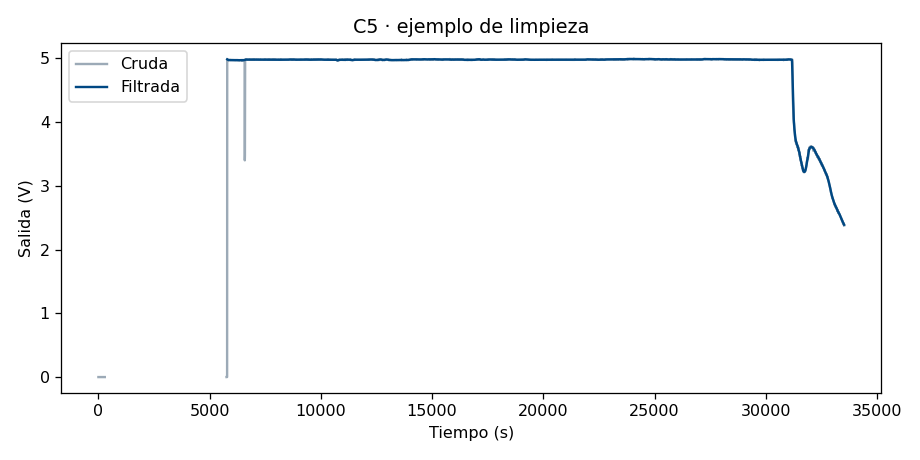

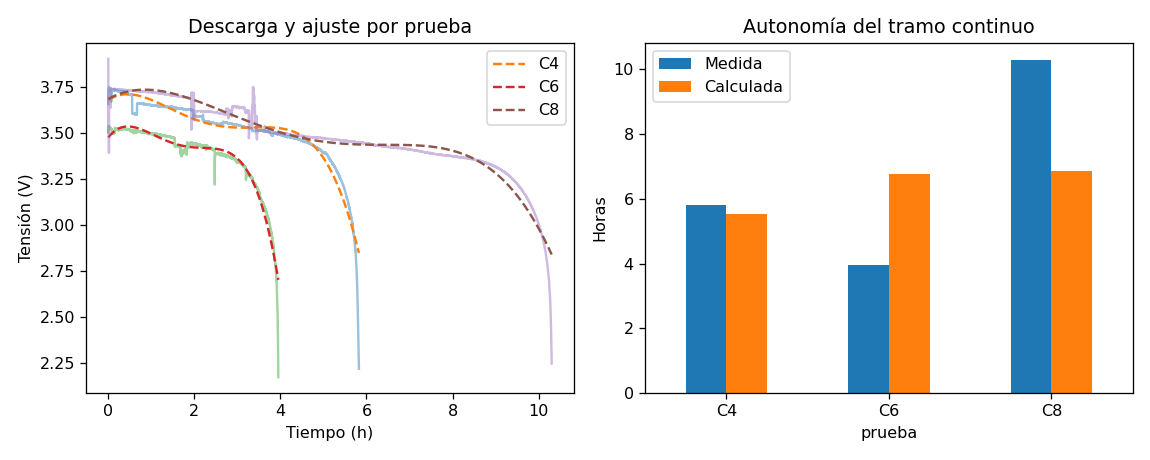

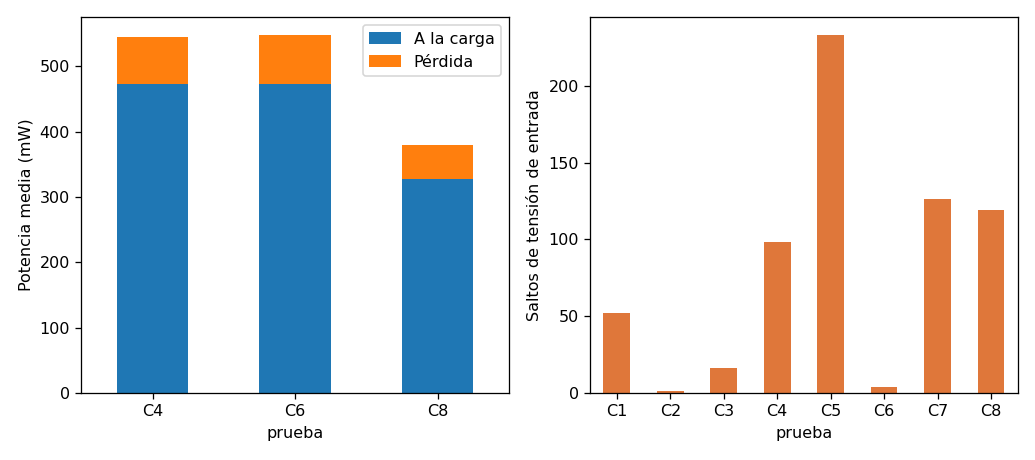

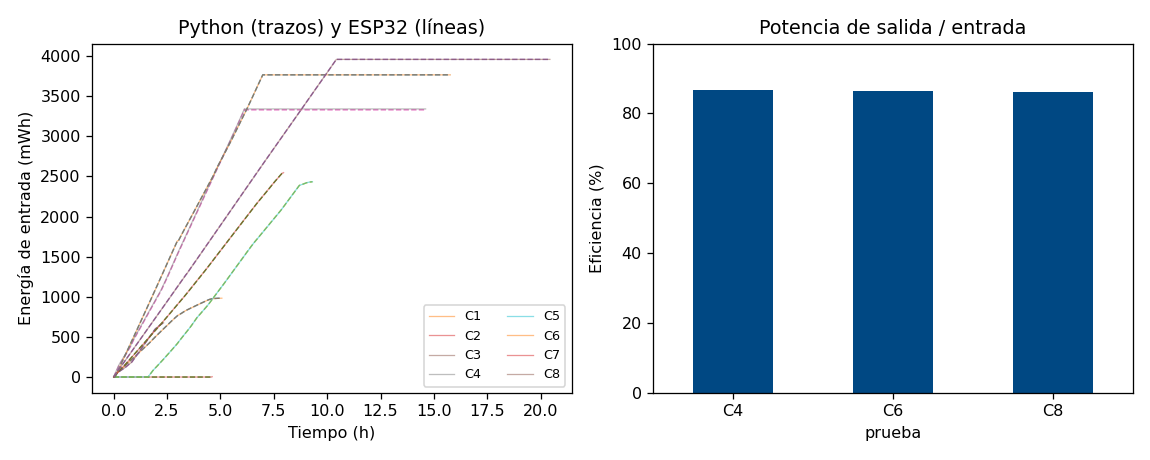

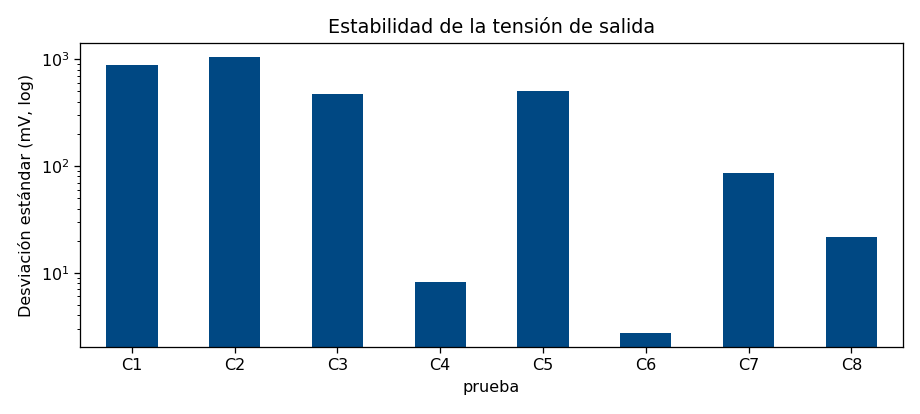

In [3]:
salida = RAIZ / 'graficas'
graficar(pruebas, tabla, curvas, autonomia, salida)
exportar(tabla, autonomia)
display(tabla.groupby('fuente')[['p_ent_mW', 'p_sal_mW', 'sigma_sal_mV']].mean().round(2))
for nombre in ('r1_limpieza', 'r2_descarga_autonomia', 'r2_perdidas', 'r3_teorico_vs_real', 'r3_estabilidad'):
    display(Image(filename=salida / (nombre + '.png')))